### Datos

In [1]:
from sklearn.datasets import load_iris


In [2]:

# Cargamos el conjunto de datos Iris
iris = load_iris()
X = iris.data
y = iris.target

# Creamos un filtro para quedarnos solo con dos clases (clasificación binaria)
filter = (y == 0) | (y == 1)
X = X[filter]
y = y[filter]

X.shape

(100, 4)

In [3]:
# Creamos unos datos de prueba para ir probando sucesivamente las funciones
X_check = X[0]
y_check = y[0]

print(X_check.shape)

(4,)


### Regresión Logística y Función Sigmoide

La regresión logística es un método estadístico para predecir clases binarias. El resultado o variable objetivo es de naturaleza dicotómica. La regresión logística predice la probabilidad de que la variable objetivo pertenezca a una de las dos clases.

La función sigmoide, también conocida como función logística, se utiliza para convertir cualquier valor real en otro valor entre 0 y 1, y se define como:

$$ \sigma(z) = \frac{1}{1 + e^{-z}} $$

Donde:
- $ \sigma(z) $ es el valor de salida de la función sigmoide.
- $ z $ es la entrada a la función, que puede ser cualquier valor real.

In [5]:
import numpy as np

# Función sigmoide, que es nuestra función de hipótesis para la regresión logística
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

## Descenso de Gradiente Estocástico

### Inicialización de parámetros

Haremos una inicialización de los pesos y ejecutaremos la iteraciones definidas.


La inicialización se realizará de forma aleatoria y con valores moderados, fundamentalmente por dos razones:


1. **Evitar la saturación temprana:** Previene la inactividad del aprendizaje por la saturación de la función sigmoide.
2. **Prevenir sobreajuste inicial:** Ayuda a evitar un ajuste excesivo temprano.

Esta práctica facilita un mejor aprendizaje y es un buen punto de partida, aunque la estrategia óptima puede variar según el caso específico.

In [6]:
def initialize_parameters_normal(p):
    """
    Esta función crea un vector de inicialización con valores aleatorios
    siguiendo una distribución normal.

    Argumento:
    p -- tamaño del vector w que queremos (o número de parámetros en este caso)

    Devuelve:
    weights -- vector inicializado de forma (p)
    b -- sesgo
    """

    # Inicializa el vector de pesos 'w' con muestras de una distribución normal
    # Se suma 1 para incluir el término del sesgo en el vector de pesos,
    w = np.random.randn(p)  # Asegúrate de que tenga la forma correcta.
    b = np.random.randn()

    return w, b


####VERIFICACIÓN DE LA FUNCIÓN#######
p = X_check.shape[0]

np.random.seed(1)
w_check, b_check= initialize_parameters_normal(p)

#Verificamos la función:
print("Verificamos initialize_parameters_normal.\n Debe salir: ", w_check, b_check)


Verificamos initialize_parameters_normal.
 Debe salir:  [ 1.62434536 -0.61175641 -0.52817175 -1.07296862] 0.8654076293246785




```
 Debe salir:  [ 1.62434536 -0.61175641 -0.52817175 -1.07296862] 0.8654076293246785
```



### Propagación Hacia Adelante y Hacia Atrás

Las derivadas parciales de J son:
\begin{align*}
    \frac{\partial J}{\partial b}(b,w) = a-y \qquad  \frac{\partial J}{\partial w_i}(b,w) = (a-y)x_i
\end{align*}



In [6]:
#@title forward_propagate
def forward_propagate(w, b, x):
    """
    Implementa la propagación hacia adelante

    Argumentos:
    w -- pesos
    x -- datos (dimensión p)

    Devuelve:
    a
    """

    # Calcula la dimensión de la observación
    p = len(x)

    # Calcula z. Primero la contribución término independiente
    z = b

    # Iteramos x
    for i in range(p):
        z += x[i]*w[i]

    # Calculamos la sigmoide
    a = sigmoid(z)

    return a

####VERIFICACIÓN DE LA FUNCIÓN#######
a_check = forward_propagate(w=w_check, b = b_check, x=X_check)

#Verificamos la función:
print("Verificamos forward_propagate.\n Debe salir: ", a_check)

Verificamos forward_propagate.
 Debe salir:  0.9976579581563737




```
Verificamos forward_propagate.
 Debe salir:  0.9976579581563737
```



Denominamos:

  * `db` $= \frac{\partial J}{\partial b}(b,w)$

  
  * `dw[i]` $= \frac{\partial J}{\partial w_i}(b,w)$

Recordamos:


\begin{align*}
        & J = - \left[ y \log a + (1 - y) \log (1 - a) \right]
\end{align*}

In [8]:
#@title backward_propagate
def backward_propagate(a, x, y):
    """
    Calcula el gradiente de la propagación hacia
    atrás y calcula también el valor de la función de coste
    para su posterior monitorización.

    Argumentos:
    x -- datos (dimensión p)
    y -- etiqueta verdadera (dimensión 1)

    Devuelve:
    J -- log-verosimilitud negativa para la regresión logística
    dw -- gradiente de la pérdida respecto a w, por lo tanto, del mismo tamaño
    que w
    db -- gradiente de la pérdida respecto a b
    """

    # Calcula las derivadas parciales
    db = a - y
    a = np.clip(a, 1e-10, 1-10e-10)
    # Iteramos las componentes del vector de entrada.
    p = len(x)
    dw = np.zeros(p)
    for i,x_i in enumerate(x):
      dw[i] = (a-y)*x_i

    # Calculamos la pérdida para monitarizar el aprendizaje
    J = -(y * np.log(a) + (1-y)*np.log(1-a))
    # Debido a un error númerico que nos había aparecido antes vemos que: 
    

    return dw,db, J

####VERIFICACIÓN DE LA FUNCIÓN#######
dw_check,db_check, J_check = backward_propagate(a=a_check, x=X_check, y=y_check)
print("Verificamos back_propagate.\n Debe salir: ", dw_check,db_check, J_check)

Verificamos back_propagate.
 Debe salir:  [5.08805559 3.49180285 1.39672114 0.19953159] 0.9976579581563737 6.056732147345254




```
Debe salir:  [5.08805559 3.49180285 1.39672114 0.19953159] 0.9976579581563737 6.056732147345254
```



### Función fit

En primer lugar se inicializan los pesos b y w de manera aleatoria. Después se repite la iteración:
  
  1. Se introduce una observación por la entrada: $x$ (de acuerdo al modelo descenso de gradiente estocástico, se elige aleatoriamente entre las observaciones)

  2. Se obtienen el valor de salida: $a$

  3. Con $a$ y $x$ podemos calcular el valor numérico del gradiente evaluado en b y w


  \begin{align*}
      & \frac{\partial J}{\partial b} = a-y  \qquad
      & \frac{\partial J}{\partial w} = (a-y)x
  \end{align*}

  4. Actualizamos los pesos de acuerdo a las ecuaciones (descenso de gradiente)


  \begin{align*}
  b := b - \eta \frac{\partial J}{\partial b} \big(b,w \big) \qquad
  w := w - \eta \frac{\partial J}{\partial w} \big(b,w \big)
  \end{align*}

In [9]:
def logistic_regression_fit(X, y, eta, iterations, seed = 42):
    """
    Entrena los parámetros de la regresión logística

    Argumentos:
    X -- datos (dimensión Nxp)
    y -- etiqueta verdadera (dimensión 1)
    eta -- tasa de aprendizaje
    iterations - número de iteraciones
    seed - semilla

    Devuelve:
    w - pesos (dimensión p)
    b - término independiente (dimensión 1)
    J_evolution -- evolución de la log-verosimilitud negativa
    """
    # Número de características
    p = X.shape[1]

    #número de ejemplos
    N = X.shape[0]


    # Inicializar los pesos (w) y el término de sesgo (b)
    w, b = initialize_parameters_normal(p)

    # Inicializamos una lista para ver la evolución de J
    J_evolution = []

    # Semilla para reproducibilidad
    np.random.seed(42)

    # Iteramos de acuerdo al número de iteraciones
    for n in range(iterations):
        # Seleccionar aleatoriamente una observación de los datos de entrenamiento
        random_index = np.random.randint(0,N)
        x_n = X[random_index]
        y_n = y[random_index]

        # 1 y 2. Se introduce una observación y se calcula a
        # mediante propagación hacia adelante
        a = forward_propagate(w, b, x_n)

        # 3. Calculamos los gradientes (también la
        # pérdida para su monitorización)
        dw, db, J = backward_propagate(a, x_n, y_n)

        # Almacenamos la pérdida
        J_evolution.append(J)

        # 4.a. Actualizar el término de bias b utilizando su derivada
        b = b - eta*db

        # 4.b. Actualizar cada peso w_i utilizando su correspondiente derivada
        for index in range(len(w)):
            w[index] = w[index] - eta*dw[index]

    # Una vez terminadas las iteraciones recuperamos los pesos actualizados
    return w, b, J_evolution

####VERIFICACIÓN DE LA FUNCIÓN#######
w_check, b_check, J_evolution_check = logistic_regression_fit(X,y,0.07,10000)

print("Verificamos logistic_regression_fit.\n Debe salir: ", w_check, b_check)

Verificamos logistic_regression_fit.
 Debe salir:  [-1.25973897 -2.1065734   4.41441152  2.81660932] -0.9106148920201295




```
 Debe salir:  [-1.96144217 -1.38142592  4.9132892   2.73357717] -0.607727376209115

```



### Probamos la función con los datos de Iris con p=1

In [31]:
from sklearn.datasets import load_iris
import matplotlib.pyplot as plt


# Cargamos el conjunto de datos Iris
iris = load_iris()
X = iris.data[:, :1]  # Tomamos solo la primera característica.
y = iris.target

# Creamos un filtro para quedarnos solo con dos clases (clasificación binaria)
filter = (y == 0) | (y == 1)
X = X[filter]
y = y[filter]

In [32]:
# Híper-parámetros de entrenamiento (Los establecemos
# un poco 'al azar')
eta = 0.7  # Tasa de aprendizaje
iterations = 10000 # Número de iteraciones

# Entrenamiento del modelo
w, b, J = logistic_regression_fit(X, y, eta, iterations, seed = 42)

# Mostrar los pesos con 2 decimales únicamente
print(f'Bias final {b:.2f}')
print(f'w final {w[0]:.2f}')

print(f'ecuación de frontera: x = {-(b/w[0]):.2f}')

Bias final -102.31
w final 14.65
ecuación de frontera: x = 6.98




```
Bias final -102.23
w final 14.63
ecuación de frontera: x = 6.99
```



La ecuación de frontera venía dada por -b/w. Utilizando las librerías nos daba un valor de aproximadamente x=5.4

Con estos parámetros de entrenamiento encontramos mucha variabilidad en la solución.

In [33]:
# Repetimos el cálculo 5 veces
for i in range(5):
  w,b,J = logistic_regression_fit(X, y, eta, iterations,seed = i)
  print(-b/w[0])

6.984120257131365
6.984120257131365
6.984120257131365
6.984120257131365
6.984120257131365




```
[5.87966981]
[4.97873553]
[6.13322471]
[5.35095567]
[4.46459273]

```



Para entender mejor el proceso de entrenamiento, vamos a monitorizarlo mediante la evolución de la función de pérdida:

In [34]:
eta = 0.01  # Tasa de aprendizaje
iterations = 10000  # Número de iteraciones

# Entrenamiento del modelo
b, w, J = logistic_regression_fit(X=X, y=y, eta=eta, iterations=iterations)

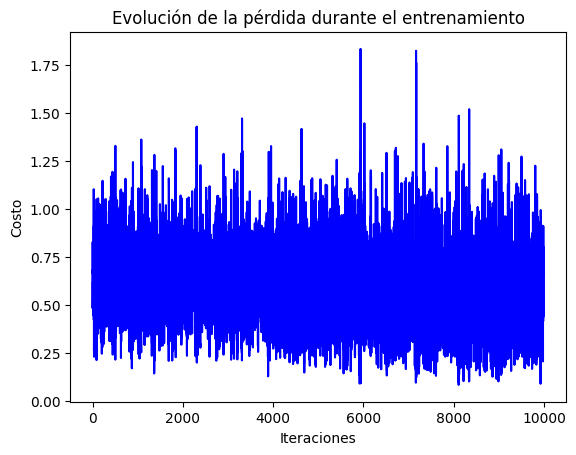

In [35]:
# Representamos la evolución de la pérdida
plt.plot(J[10:], color='blue')
plt.title('Evolución de la pérdida durante el entrenamiento')
plt.xlabel('Iteraciones')
plt.ylabel('Costo')
plt.show()

Lo representamos para diferentes valores de $\eta$

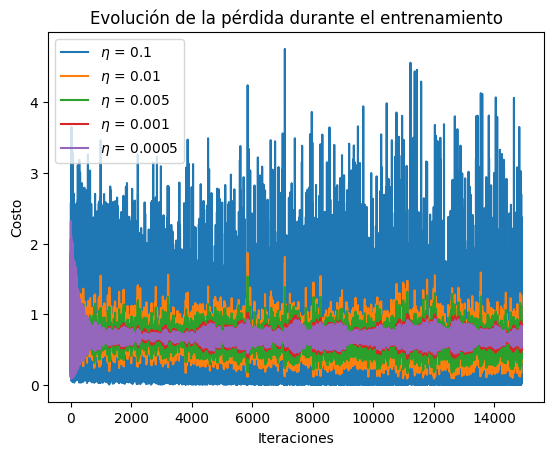

In [36]:
import numpy as np
import matplotlib.pyplot as plt

# Definir diferentes tasas de aprendizaje para experimentar con ellas
etas = [0.1, 0.01, 0.005, 0.001, 0.0005]

# Establecer el número total de iteraciones para el entrenamiento
iterations = 15000

# Iterar sobre cada tasa de aprendizaje
for eta in etas:
    # Establecer una semilla (1) para la reproducibilidad de los resultados
    np.random.seed(42)

    # Ejecutar la regresión logística estocástica (SGD) con la tasa de aprendizaje actual
    b, w, J = logistic_regression_fit(X=X, y=y, eta=eta, iterations=iterations)

    # Representar la evolución de la pérdida después de las primeras 100 iteraciones
    # para evitar grandes valores iniciales que distorsionan la escala del gráfico
    plt.plot(J[100:], label = '$\\eta$ = ' + str(eta))

# Configurar el título y las etiquetas del gráfico
plt.title('Evolución de la pérdida durante el entrenamiento')
plt.xlabel('Iteraciones')
plt.ylabel('Costo')

# Mostrar la leyenda
plt.legend()

# Mostrar el gráfico
plt.show()


### Función Predict

Hasta aquí estábamos analizando la evolución del error de entrenamiento. Ahora vamos a estudiar la evolución de cara al error de test o de generalización.

Para ello vamos a estudiar la precisión o accuracy, que nos indica el porcentaje de observaciones de test que el algoritmo es capaz de acerta.

In [37]:
def logistic_regression_predict(X, w, b):
    """
    Predice las clases mediante la propagación hacia adelante.

    Argumentos:
    X -- datos (dimensión Nxp)
    w - pesos (dimensión p)
    b - término independiente (dimensión 1)

    Devuelve:
    predictions -- predicciones para las N observaciones (dimensión N)

    """

    # Inicializar una lista para almacenar las predicciones
    predictions = []

    N = X.shape[0]

    # Iterar a través de las observaciones:
    for i in N:

        # propagación hacia adelante
        x = X[i]
        a = forward_propagate(w, b, x)

        # Determinar si la predicción es 0 o 1
        prediction = 1 if a >= 0.5 else 0
        predictions.append(prediction)

    # Convertir la lista de predicciones a un array de NumPy para facilitar el cálculo de la precisión
    predictions = np.array(predictions)
    return predictions

In [38]:
def calculate_accuracy(predictions, y):

    # Calcular y devolver accuracy como el porcentaje de predicciones correctas
    mask = predictions == y
    accuracy = mask.mean()
    return accuracy


Calculamos el accuracy para diferentes número de iteraciones

In [40]:
from sklearn.model_selection import train_test_split

# Separamos train y test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)  # test_size=0.3 significa que el 30% de los datos se utilizará como conjunto de prueba

# Calculamos la precisión del algoritmo para diferentes números de iteraciones
# teniendo en cuenta el gráfico anterior a la hora de elegir eta
eta = 0.01

iterations = [500, 1000, 5000, 10000, 15000]

for iteration in iterations:
    w, b, J = logistic_regression_fit(X=X_train, y=y_train, eta=eta, iterations=iteration)

    predictions = logistic_regression_predict(X=X_test, w=w, b=b)
    accuracy = calculate_accuracy(predictions, y_test)

    print(f"Iteraciones: {iteration}, Accuracy: {accuracy}")



TypeError: 'int' object is not iterable

Se podrían hacer experimentos más detallados para ajustar los hiperparámetros, pero la conclusión principal, es que esta implementación del descenso de gradiente estocástico tiene un proceso de entrenamiento con un comportamiento muy inestable.

### Probamos con p=2

In [ ]:

# Cargamos el conjunto de datos Iris
iris = load_iris()
X = iris.data[:, :2]  # Tomamos solo la primera característica.
y = iris.target

# Creamos un filtro para quedarnos solo con dos clases (clasificación binaria)
filter = (y == 0) | (y == 1)
X = X[filter]
y = y[filter]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [ ]:
# Calculamos la precisión del algoritmo para diferentes números de iteraciones
# teniendo en cuenta el gráfico anterior a la hora de elegir eta
eta = 0.01

iterations = [500, 1000, 5000, 10000, 15000]

for iteration in iterations:
    ___

    ___

    ___
    print(f'Precisión con {eta}: {accuracy:.2f}%')

Precisión con 0.01: 43.33%
Precisión con 0.01: 100.00%
Precisión con 0.01: 100.00%
Precisión con 0.01: 100.00%
Precisión con 0.01: 100.00%
